# 项目：分析鸢尾花种类数据

## 分析目标

此数据分析报告的目的是基于鸢尾花的属性数据，分析两种鸢尾花萼片、花瓣的长度和宽度平均值，是否存在显著性差异，让我们可以对不同种类鸢尾花的属性特征进行推断。

## 简介

原始数据`Iris.csv`包括两种鸢尾花，每种有 50 个样本，以及每个样本的一些属性，包括萼片的长度和宽度、花瓣的长度和宽度。

`Iris.csv`每列的含义如下：
- Id：样本的ID。
- SepalLengthCm：萼片的长度（单位为厘米）。
- SepalWidthCm：萼片的宽度（单位为厘米）。
- PetalLengthCm：花瓣的长度（单位为厘米）。
- PetalWidthCm：花瓣的宽度（单位为厘米）。
- Species：鸢尾花种类。

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
Yuan=pd.read_csv(r"C:\Users\30338\Desktop\数据处理学习\5数据分析\Iris.csv")
Yuan.head(10)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa
6,7,4.6,3.4,1.4,0.3,Iris-setosa
7,8,5.0,3.4,1.5,0.2,Iris-setosa
8,9,4.4,2.9,1.4,0.2,Iris-setosa
9,10,4.9,3.1,1.5,0.1,Iris-setosa


#### 一、数据清洗  
从结构上和内容上对Yuan进行清洗。结构上干净整齐的数据都是相似的。  
整洁数据包含三个特点:1.每列是一个变量 2.每行是一个观察值 3.每个单元格是一个值。  
经过观察发现，Yuan满足结构上整洁数据的要求，因此不对其进行结构上的清洗。  
接下来是内容上的清洗：包括重复、不一致、无效或错误数据、亦或者是数据类型需要的转换。

In [39]:
c_yuan=Yuan.copy()
c_yuan.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             100 non-null    int64  
 1   SepalLengthCm  100 non-null    float64
 2   SepalWidthCm   100 non-null    float64
 3   PetalLengthCm  100 non-null    float64
 4   PetalWidthCm   100 non-null    float64
 5   Species        100 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 4.8 KB


##### 经观察发现，数据不存在缺失，但是ID作为编号应当为字符串而非数字，因此应该对其进行数据类型的转换。

In [40]:
c_yuan["Id"]=c_yuan["Id"].astype(str)
c_yuan.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             100 non-null    str    
 1   SepalLengthCm  100 non-null    float64
 2   SepalWidthCm   100 non-null    float64
 3   PetalLengthCm  100 non-null    float64
 4   PetalWidthCm   100 non-null    float64
 5   Species        100 non-null    str    
dtypes: float64(4), str(2)
memory usage: 4.8 KB


In [41]:
Yuan.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,50.500000,5.471000,3.094000,2.862000,0.785000
std,29.011492,0.641698,0.476057,1.448565,0.566288
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,25.750000,5.000000,2.800000,1.500000,0.200000
50%,50.500000,5.400000,3.050000,2.450000,0.800000
75%,75.250000,5.900000,3.400000,4.325000,1.300000
max,100.000000,7.000000,4.400000,5.100000,1.800000


##### 经观察也并不存在脱离实际的数据，不对无效数据进行处理

#### 处理重复变量  
Id作为唯一标识符不可以存在重复，因此对其进行观察。

In [42]:
c_yuan.duplicated("Id").sum()

np.int64(0)

##### 经观察发现ID并不存在重复值  
接下来对不一致数据进行处理，不一致数据可能存在在种类里，接下来对种类进行观察。

In [43]:
c_yuan["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Name: count, dtype: int64

##### 经观察发现种类为2且比较统一，并未出现不一致数据。  
此时还可以将其类型转换成category，从而节省空间并说明类型有限。

In [44]:
c_yuan["Species"]=c_yuan["Species"].astype("category")
c_yuan["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Name: count, dtype: int64

### 整理数据
对数据的整理，与分析方向紧密相关。此次数据分析目标是：基于鸢尾花的属性数据，分析两种鸢尾花萼片、花瓣的长度和宽度平均值，是否存在显著性差异。那么我们可以对数据基于`Species`列，先把各个鸢尾花种类样本数据筛选出来。

In [45]:
fs=c_yuan.query("Species=='Iris-setosa'")
fs.head(10)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa
6,7,4.6,3.4,1.4,0.3,Iris-setosa
7,8,5.0,3.4,1.5,0.2,Iris-setosa
8,9,4.4,2.9,1.4,0.2,Iris-setosa
9,10,4.9,3.1,1.5,0.1,Iris-setosa


In [46]:
fv=c_yuan.query("Species=='Iris-versicolor'")
fv.head(10)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
50,51,7.0,3.2,4.7,1.4,Iris-versicolor
51,52,6.4,3.2,4.5,1.5,Iris-versicolor
52,53,6.9,3.1,4.9,1.5,Iris-versicolor
53,54,5.5,2.3,4.0,1.3,Iris-versicolor
54,55,6.5,2.8,4.6,1.5,Iris-versicolor
55,56,5.7,2.8,4.5,1.3,Iris-versicolor
56,57,6.3,3.3,4.7,1.6,Iris-versicolor
57,58,4.9,2.4,3.3,1.0,Iris-versicolor
58,59,6.6,2.9,4.6,1.3,Iris-versicolor
59,60,5.2,2.7,3.9,1.4,Iris-versicolor


In [47]:
print(len(fs),len(fv))

50 50


### 探索数据

在着手推断统计学分析之前，可以先借助数据可视化，探索`Setosa`和`Versicolor`这两种鸢尾花的变量特点。

可视化探索可以对数据有一个更直观的理解，比如了解数据的分布、发现变量之间的关系，等等，从而为后续的进一步分析提供方向。

针对数值，我们可以直接绘制成对图，利用其中的密度图查看不同变量的分布，以及利用散点图了解变量之间的关系。

并且，由于此次分析目的是了解不同种类鸢尾花的属性特征是否存在差异，我们可以利用颜色对图表上不种类类的样本进行分类。

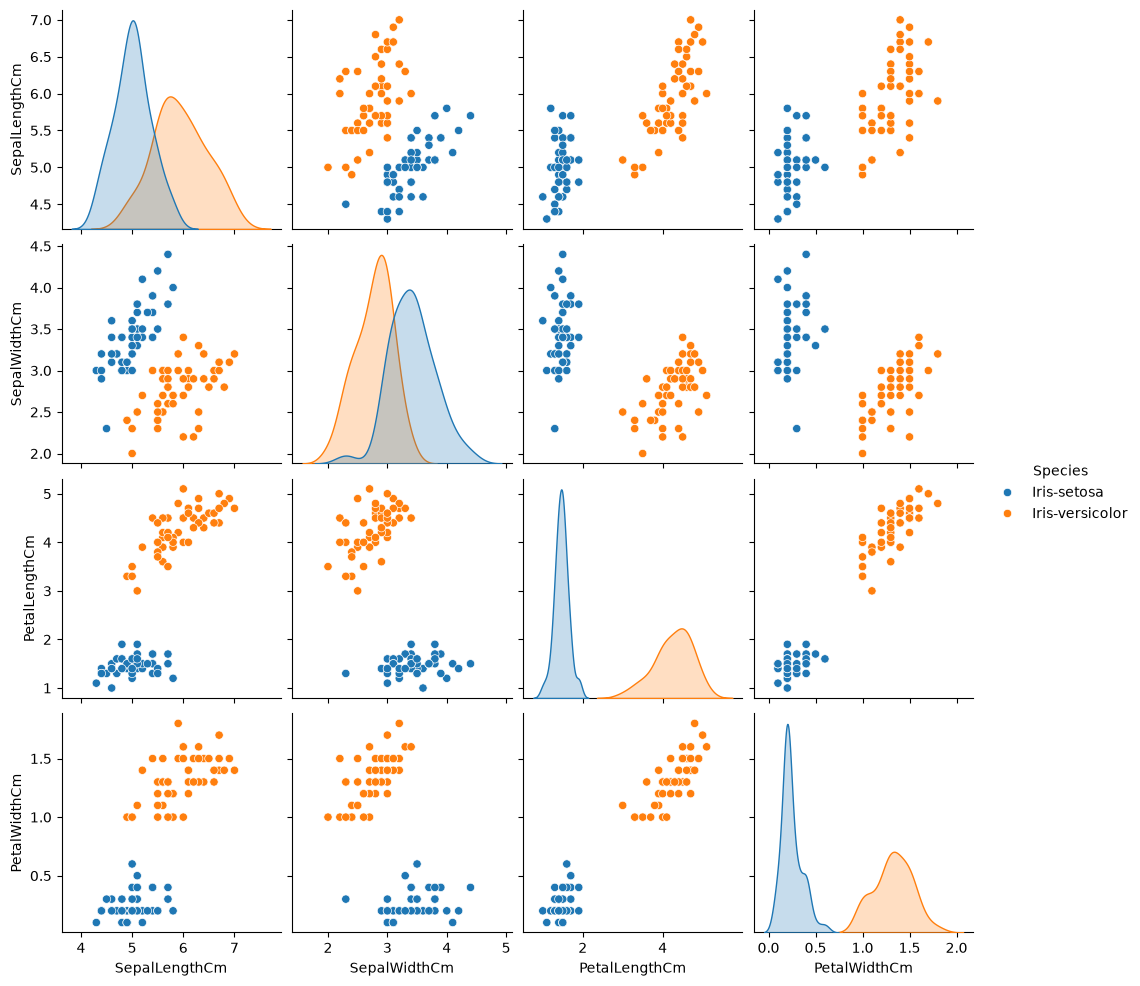

In [48]:
sns.pairplot(c_yuan,hue="Species")

#### 通过上方的成对图可以假设检验结果为花瓣长度和宽度存在统计显著性差异  
但是萼片的长和宽存在重叠，无法立刻下定论，需要进行假设检验，从而推断是否存在差异。

### 分析数据

我们将利用假设检验，依次检验`Setosa`和`Versicolor`这两种鸢尾花在萼片、花瓣的长度和宽度平均值方面，是否存在统计显著性差异。  
由于只有样本数据，没有总体标准差，两组样本数各为50，数量不大，因此进行t检验。  
假设此数据集样本符合t检验的两个前提：样本为随机抽样，总体呈正态分布。  
要先引入t检验所需要的模块。

In [49]:
from scipy.stats import ttest_ind

#### 对萼片长度进行分析
首先查看两个种类分别呈现什么样的分布。 


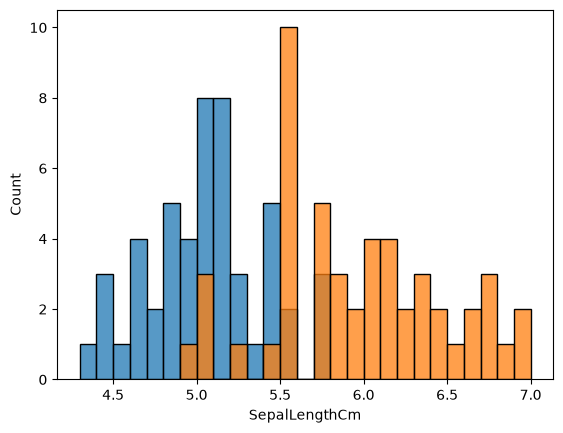

In [50]:
sns.histplot(fs["SepalLengthCm"],binwidth=0.1)
sns.histplot(fv["SepalLengthCm"],binwidth=0.1)
plt.show()

##### 建立假设
$H_0$：S和V两种花萼片长度之间不存在显著性差异  
$H_1$：S和V两种花萼片长度之间存在显著性差异.

#### 确定是单尾还是双尾检验  
由于不是比萼片谁长，因此应该是双尾检验。

#### 确定显著水平  
双尾检验一般显著水平为0.05

#### 计算t和p值

In [ ]:
t_stat,p_value = ttest_ind(fs["SepalWidthCm"],fv["SepalWidthCm"])
print(f"t值：{t_stat}")
print(f"p值：{p_value}")

t值：-10.52098626754911
p值：8.985235037487147e-18


### 结论  
由于p小于显著水平0.05，因此应当拒绝原假设，说明fs和fv两种花之间的长度平均值存在显著区别。

### 分析萼片宽度  
按照以上流程走一遍即可

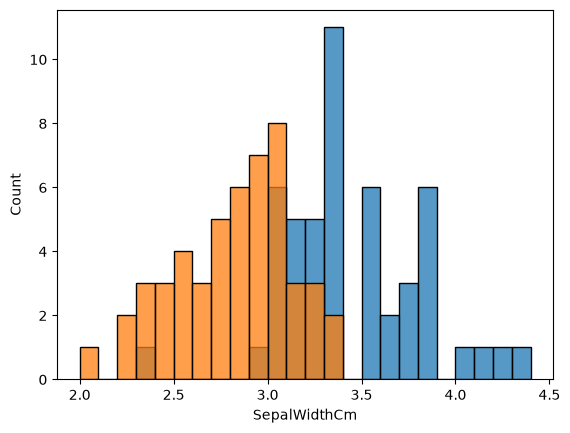

In [53]:
sns.histplot(fs["SepalWidthCm"],binwidth=0.1)
sns.histplot(fv["SepalWidthCm"],binwidth=0.1)
plt.show()

#### 建立假设  
$H_0$：S和V两种花萼片宽度之间不存在显著性差异  
$H_1$：S和V两种花萼片宽度之间存在显著性差异.

#### 确定单尾双尾

由于不是比萼片谁宽，因此应该是双尾检验。


#### 确定显著水平
双尾检验一般显著水平为0.05

### 计算T和p值

In [54]:
t_stat,p_value = ttest_ind(fs["SepalWidthCm"],fv["SepalWidthCm"])
print(f"t值：{t_stat}")
print(f"p值：{p_value}")

t值：9.282772555558111
p值：4.3622390160102135e-15


#### p值小于0.05，应该拒绝原假设，因此存在统计学显著性差异。

## 花瓣的分析同上